# Кому предлагать «Зерно+»

## 1. Цель
На дату 1 июля 2026 выбрать адресатов предложения, используя только доступную на эту дату информацию. V=1600 ₽ за покупку за три месяца, C=150 ₽ за каждый контакт. Решение по дополнительной марже относительно контроля. До расчётов фиксирую максимум неотрицательной OOF дополнительной маржи на сетке .02–.40, при равенстве меньший порог; мощность не более 300 контактов на 1350 обучающих кандидатов. Для поправки нужно минимум 20 выбранных контролей. Если вариантов нет — отказ.

Это собственное воспроизводимое решение, не буквальное воспроизведение единственного порога браузерной карточки. Из контроля заранее отложена треть для независимого финального сравнения.

In [1]:
import os,json,platform,sqlite3
from pathlib import Path
import numpy as np
import pandas as pd
import sklearn
import matplotlib.pyplot as plt
from IPython.display import display,Markdown
from sklearn.model_selection import train_test_split,StratifiedKFold,cross_val_score,cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.compose import make_column_transformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder,StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier,HistGradientBoostingClassifier
from sklearn.metrics import roc_auc_score,average_precision_score
RANDOM_STATE=42
DATA=Path(os.environ.get('COURSE_DATA','../technical/data-baseline'))
OUT=Path('subscription-artifacts');OUT.mkdir(exist_ok=True)
V,C=1600,150
versions={'python':platform.python_version(),'numpy':np.__version__,'pandas':pd.__version__,'sklearn':sklearn.__version__,'runtime':'native Python, separate from browser Pyodide'}
print(versions)


{'python': '3.12.14', 'numpy': '2.4.6', 'pandas': '3.0.6', 'sklearn': '1.8.0', 'runtime': 'native Python, separate from browser Pyodide'}


## 2. Данные и 3. Предобработка
База final1.db из учебного пакета, путь COURSE_DATA либо ../technical/data-baseline. Все событийные запросы срезаны до 1 июля; июль используется только для диагностического демонстрирования утечки, не в X. У sessions/complaints отсутствие = 0, неизвестный средний чек остаётся NaN. Возраст 1900 превращён в NaN и используется только для аудита. Соединения проверяют гранулярность.

In [2]:
con=sqlite3.connect(DATA/'final1.db')
CUTOFF='2026-07-01'
params={'cutoff':CUTOFF,'month':'2026-07'}
data=pd.read_sql_query("SELECT g.*,s.city FROM guests g LEFT JOIN shops s ON g.home_shop_id=s.shop_id",con)
assert len(data)==4800 and data.guest_id.is_unique
agg=pd.read_sql_query("""SELECT guest_id,COUNT(*) AS orders_n,
julianday(:cutoff)-julianday(MAX(ordered_at)) AS recency_days,
AVG(amount) AS avg_check,AVG(channel='доставка') AS delivery_share,
AVG(CAST(strftime('%H',ordered_at) AS INTEGER)<10 AND strftime('%w',ordered_at) NOT IN ('0','6')) AS morning_share,
COUNT(DISTINCT shop_id) AS shops_n
FROM orders WHERE ordered_at<:cutoff GROUP BY guest_id""",con,params=params)
coffee=pd.read_sql_query("""SELECT o.guest_id,AVG(m.category='кофе') AS coffee_share
FROM orders o JOIN order_items i ON o.order_id=i.order_id JOIN menu m ON i.item_id=m.item_id
WHERE o.ordered_at<:cutoff GROUP BY o.guest_id""",con,params=params)
app=pd.read_sql_query("SELECT guest_id,SUM(sessions) AS app_sessions FROM app_sessions WHERE month<:month GROUP BY guest_id",con,params=params)
compl=pd.read_sql_query("SELECT guest_id,COUNT(*) AS complaints_n FROM complaints WHERE created_at<:cutoff GROUP BY guest_id",con,params=params)
for part in [agg,coffee,app,compl]:
    n=len(data)
    data=data.merge(part,on='guest_id',how='left',validate='one_to_one')
    assert len(data)==n
for c in ['orders_n','shops_n','app_sessions','complaints_n']:
    data[c]=data[c].fillna(0)
data['tenure_days']=(pd.Timestamp(CUTOFF)-pd.to_datetime(data.reg_date)).dt.total_seconds()/86400
data['orders_per_week']=data.orders_n/(data.tenure_days.clip(upper=122)/7)
data['birth_year']=data.birth_year.mask(data.birth_year==1900)
pilot=pd.read_sql_query('SELECT * FROM pilot',con)
assert len(pilot)==2400 and pilot.guest_id.is_unique
off=pilot[pilot.group_name=='предложение'].merge(data,on='guest_id',validate='one_to_one')
assert len(off)==1800


In [3]:
print('Гостей',len(data),'с заказами',int(data.orders_n.gt(0).sum()),'пилот',len(pilot),'предложение',len(off))
display(data[['orders_n','orders_per_week','app_sessions','morning_share','delivery_share','coffee_share']].mean().round(3))
display(data.isna().sum().to_frame('missing'))


Гостей 4800 с заказами 4387 пилот 2400 предложение 1800


orders_n            7.482
orders_per_week     0.473
app_sessions       15.576
morning_share       0.351
delivery_share      0.115
coffee_share        0.551
dtype: float64

,missing
guest_id,0
reg_date,0
source,0
home_shop_id,0
birth_year,462
city,0
orders_n,0
recency_days,413
avg_check,413
delivery_share,413


**Вывод по сборке.** Контроль уникальности и assert числа строк защищают каждое соединение агрегатов. Недельная частота делит на окно от регистрации, но не раньше марта; давность считается от среза, поэтому запуск в другой день не меняет X.

## 4. Анализ и модели

,size,mean
morning_share,,
до 0.2,675,0.033
0.2–0.5,685,0.082
выше 0.5,440,0.273


,size,mean
source,,
касса,1060,0.087
приложение,740,0.143


,size,mean
city,,
Казань,729,0.125
Пермь,570,0.118
Тюмень,282,0.060
Уфа,219,0.105


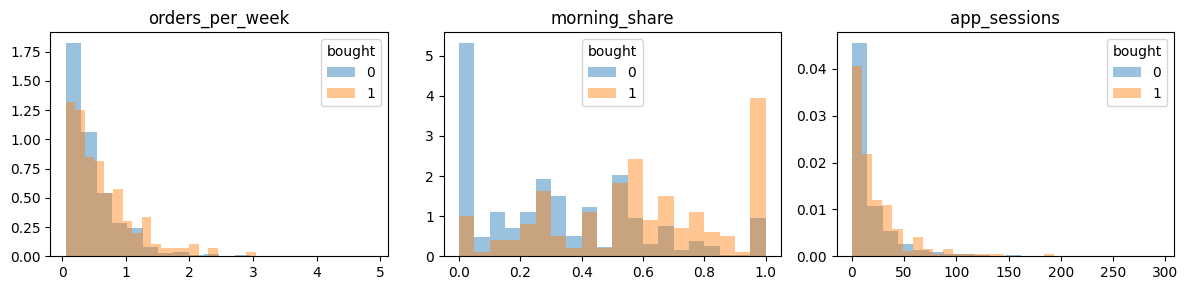

Конверсии 0.11 0.025 Прирост п.п. 8.5 Порог эффекта 0.09375
Валово всем 46800 Дополнительно на предложение -14.0
Диагностика утечки 0.8914141414141414 Честная частота 0.5905906757966684


**Вывод по разведке.** Группа утренней доли >0.5 покупает с частотой 27.3%, весь пилот предложения — 11.0%. Сравнены также канал регистрации и город. При цене контакта 150 ₽ стратегия всем даёт -14 ₽ дополнительной маржи на контакт. Это причина перейти к отбору, а не обещать успех любой рассылки. Утечка 0.891 после среза исключена из модели.

In [4]:
groups=pd.cut(off.morning_share,[0,.2,.5,1],include_lowest=True,labels=['до 0.2','0.2–0.5','выше 0.5'])
by_morning=off.groupby(groups,observed=True).bought.agg(['size','mean'])
by_source=off.groupby('source').bought.agg(['size','mean'])
by_city=off.groupby('city').bought.agg(['size','mean'])
display(by_morning.round(3),by_source.round(3),by_city.round(3))
fig,axes=plt.subplots(1,3,figsize=(12,3))
for ax,col in zip(axes,['orders_per_week','morning_share','app_sessions']):
    for bought in [0,1]:
        ax.hist(off.loc[off.bought==bought,col].dropna(),bins=20,density=True,alpha=.45,label=str(bought))
    ax.set_title(col);ax.legend(title='bought')
fig.tight_layout();fig.savefig(OUT/'eda.png');plt.show()
ctrl_all=pilot[pilot.group_name=='контроль'].merge(data,on='guest_id',validate='one_to_one')
conv_offer=off.bought.mean();conv_ctrl=ctrl_all.bought.mean()
print('Конверсии',conv_offer,conv_ctrl,'Прирост п.п.',100*(conv_offer-conv_ctrl),'Порог эффекта',C/V)
print('Валово всем',V*off.bought.sum()-C*len(off),'Дополнительно на предложение',(conv_offer-conv_ctrl)*V-C)
leak=pd.read_sql_query("SELECT guest_id,AVG(payment='абонемент') AS sub_share FROM orders GROUP BY guest_id",con)
leak_off=off.merge(leak,on='guest_id',how='left',validate='one_to_one')
auc_leak=roc_auc_score(leak_off.bought,leak_off.sub_share.fillna(0))
auc_clean=roc_auc_score(off.bought,off.orders_per_week)
print('Диагностика утечки',auc_leak,'Честная частота',auc_clean)
con.close()
display(Markdown(f'**Вывод по разведке.** Группа утренней доли >0.5 покупает с частотой {by_morning.loc["выше 0.5","mean"]:.1%}, весь пилот предложения — {conv_offer:.1%}. Сравнены также канал регистрации и город. При цене контакта 150 ₽ стратегия всем даёт {((conv_offer-conv_ctrl)*V-C):.0f} ₽ дополнительной маржи на контакт. Это причина перейти к отбору, а не обещать успех любой рассылки. Утечка {auc_leak:.3f} после среза исключена из модели.'))


In [5]:
num=['orders_n','orders_per_week','recency_days','avg_check','delivery_share','morning_share','shops_n','tenure_days','coffee_share','app_sessions','complaints_n']
cat=['source','city']
X,y=off[num+cat],off.bought
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=.25,random_state=42,stratify=y)
cv=StratifiedKFold(n_splits=5,shuffle=True,random_state=42)
def prep_model(scale=True):
    numeric=make_pipeline(SimpleImputer(strategy='median'),StandardScaler()) if scale else SimpleImputer(strategy='median')
    return make_column_transformer((numeric,num),(OneHotEncoder(handle_unknown='ignore'),cat))
def lr_model():
    return make_pipeline(prep_model(),LogisticRegression(max_iter=1000))


In [6]:
models=[('константа',make_pipeline(prep_model(False),DummyClassifier())),('логрегрессия',lr_model()),('лес',make_pipeline(prep_model(False),RandomForestClassifier(n_estimators=100,max_depth=8,min_samples_leaf=10,random_state=42,n_jobs=1))),('бустинг',make_pipeline(prep_model(False),HistGradientBoostingClassifier(max_depth=3,learning_rate=.05,max_iter=200,random_state=42)))]
cv_rows=[];fold_scores={}
for name,model in models:
    scores=cross_val_score(model,X_train,y_train,cv=cv,scoring='roc_auc',n_jobs=1)
    fold_scores[name]=scores
    cv_rows.append({'model':name,'auc_mean':scores.mean(),'auc_std':scores.std()})
cv_table=pd.DataFrame(cv_rows)
best_name=cv_table.loc[cv_table.auc_mean.idxmax(),'model']
assert best_name=='логрегрессия','Review unexpected CV result before selecting a pipeline'
display(cv_table.round(3))
print('Парные разницы LR−бустинг',fold_scores['логрегрессия']-fold_scores['бустинг'])
cv_table.to_csv(OUT/'cv.csv',index=False)
display(Markdown('**Вывод по моделям.** Выбор по общей CV только обучающих предложений; тест ещё не используется. Показываю парные разницы с бустингом, разброс отдельной модели не является тестом равенства. Простой pipeline регрессии выбран по лучшему среднему и пригодности передачи.'))


,model,auc_mean,auc_std
0,константа,0.500,0.000
1,логрегрессия,0.825,0.026
2,лес,0.796,0.033
3,бустинг,0.816,0.025


Парные разницы LR−бустинг [0.00486479 0.00986111 0.01958333 0.00361111 0.00583333]


**Вывод по моделям.** Выбор по общей CV только обучающих предложений; тест ещё не используется. Показываю парные разницы с бустингом, разброс отдельной модели не является тестом равенства. Простой pipeline регрессии выбран по лучшему среднему и пригодности передачи.

### Порог и независимая проверка
Валовая маржа не является эффектом рассылки. Для каждого порога вычитаю покупки сопоставимого отобранного контроля. Политика выбирается на OOF train; тестовые предложенные гости и отложенные контроли открываются после фиксации порога.

In [7]:
# Split the 600 controls before policy search to preserve independent final comparison.
ctrl_train,ctrl_test=train_test_split(ctrl_all,test_size=1/3,random_state=42,stratify=ctrl_all.bought)
best=lr_model()
oof=cross_val_predict(best,X_train,y_train,cv=cv,method='predict_proba',n_jobs=1)[:,1]
best.fit(X_train,y_train)
pc_train=best.predict_proba(ctrl_train[num+cat])[:,1]
rows=[]
for t in np.arange(.02,.41,.02).round(2):
    send=oof>t;cs=pc_train>t
    n=int(send.sum());cn=int(cs.sum())
    rate=ctrl_train.loc[cs,'bought'].mean() if cn else np.nan
    margin=V*(y_train[send].sum()-rate*n)-C*n if cn else np.nan
    rows.append({'threshold':t,'sent':n,'buyers':int(y_train[send].sum()),'control_n':cn,'control_buyers':int(ctrl_train.loc[cs,'bought'].sum()),'control_rate':rate,'incremental':margin,'gross':V*y_train[send].sum()-C*n})
curve=pd.DataFrame(rows)
# Fixed capacity: at most 300 contacts per 1350 training prospects; control needs >=20 guests.
valid=curve[(curve.sent<=300)&(curve.control_n>=20)&(curve.incremental>=0)]
best_t=float(valid.loc[valid.incremental.idxmax(),'threshold']) if len(valid) else None
print('Зафиксированный порог',best_t,'мощность 300/1350')
display(curve.round(3))
curve.to_csv(OUT/'policy-curve.csv',index=False)
# Only now unlock the held-out offered guests and controls.
pt=best.predict_proba(X_test)[:,1]
pct=best.predict_proba(ctrl_test[num+cat])[:,1]
st=pt>best_t if best_t is not None else np.zeros(len(pt),dtype=bool)
sct=pct>best_t if best_t is not None else np.zeros(len(pct),dtype=bool)
rate_test=ctrl_test.loc[sct,'bought'].mean() if sct.any() else np.nan
n_test=int(st.sum());buyers_test=int(y_test[st].sum())
gross_test=V*buyers_test-C*n_test
incremental_test=V*(buyers_test-rate_test*n_test)-C*n_test if sct.any() else np.nan
auc_test=roc_auc_score(y_test,pt)
cal=pd.DataFrame({'p':pt,'bought':y_test.to_numpy()})
cal['bin']=pd.cut(cal.p,[0,.05,.1,.2,.4,1],include_lowest=True)
calibration=cal.groupby('bin',observed=True).agg(n=('bought','size'),pred=('p','mean'),fact=('bought','mean'))
display(calibration.round(3))
print('Тест AUC',auc_test,'AP',average_precision_score(y_test,pt),'n/buyers',n_test,buyers_test,'gross',gross_test,'incremental',incremental_test,'контроль n/покупки',int(sct.sum()),int(ctrl_test.loc[sct,'bought'].sum()))
# Conditional empirical uncertainty of selected test rates; no retraining/model-selection uncertainty.
rng=np.random.default_rng(2026)
y1=y_test[st].to_numpy();y0=ctrl_test.loc[sct,'bought'].to_numpy()
boots=[]
if len(y1) and len(y0):
    for _ in range(2000):
        a=rng.choice(y1,len(y1),replace=True).mean()
        b=rng.choice(y0,len(y0),replace=True).mean()
        boots.append(V*(a-b)-C)
ci=np.percentile(boots,[2.5,97.5]) if boots else np.array([np.nan,np.nan])
print('95% bootstrap интервал дополнительной маржи на контакт:',ci)
calibration.to_csv(OUT/'calibration.csv')
display(Markdown(f'**Вывод по независимой проверке.** Порог {best_t} выбран без теста по дополнительной марже при мощности 300 контактов на 1350 кандидатов и минимум 20 контролей. На новых предложенных гостях {n_test} контактов, {buyers_test} покупок; валовая маржа {gross_test:,.0f} ₽ и оценка дополнительной {incremental_test:,.0f} ₽. Контроль отложен отдельно: {int(sct.sum())} выбранных гостей. Интервал на контакт [{ci[0]:,.0f}; {ci[1]:,.0f}] ₽ показывает неопределённость редких покупок. После этого модель/порог не меняются.'))


Зафиксированный порог 0.22 мощность 300/1350


,threshold,sent,buyers,control_n,control_buyers,control_rate,incremental,gross
0,0.02,983,147,286,10,0.035,32756.993,87750
1,0.04,779,137,217,10,0.046,44912.212,102350
2,0.06,645,131,190,10,0.053,58534.211,112850
3,0.08,541,127,166,10,0.060,69905.422,122050
4,0.10,456,117,134,10,0.075,64352.239,118800
5,0.12,386,105,120,9,0.075,63780.000,110100
6,0.14,334,96,105,9,0.086,57694.286,103500
7,0.16,309,91,89,9,0.101,49254.494,99250
8,0.18,278,87,78,8,0.103,51879.487,97500
9,0.20,247,82,72,8,0.111,50238.889,94150


,n,pred,fact
bin,,,
"(-0.001, 0.05]",214,0.019,0.014
"(0.05, 0.1]",91,0.074,0.055
"(0.1, 0.2]",67,0.146,0.119
"(0.2, 0.4]",47,0.290,0.319
"(0.4, 1.0]",31,0.520,0.581


Тест AUC 0.8683393556924017 AP 0.4795224791481956 n/buyers 70 30 gross 37500 incremental 29100.0 контроль n/покупки 40 3
95% bootstrap интервал дополнительной маржи на контакт: [192.85714286 633.        ]


**Вывод по независимой проверке.** Порог 0.22 выбран без теста по дополнительной марже при мощности 300 контактов на 1350 кандидатов и минимум 20 контролей. На новых предложенных гостях 70 контактов, 30 покупок; валовая маржа 37,500 ₽ и оценка дополнительной 29,100 ₽. Контроль отложен отдельно: 40 выбранных гостей. Интервал на контакт [193; 633] ₽ показывает неопределённость редких покупок. После этого модель/порог не меняются.

### Исторические кандидаты и группы
Фиксированную модель после оценки переобучаю на всех предложенных гостях. Прогноз будущей маржи опирается на калибровку и переносимость контрольного эффекта; это условный прогноз, не доказанный итог следующей рассылки.

In [8]:
# Refit the fixed chosen pipeline for deployment after final evaluation.
final=lr_model().fit(X,y)
rest=data[(~data.guest_id.isin(pilot.guest_id))&(data.orders_n>0)].copy()
rest['p']=final.predict_proba(rest[num+cat])[:,1]
# Operational cap extrapolated from the fixed training capacity; ties resolved by guest_id.
cap=int(np.floor(len(rest)*300/1350))
rest['send']=False
eligible=rest[rest.p>best_t].sort_values(['p','guest_id'],ascending=[False,True]) if best_t is not None else rest.iloc[:0]
ids=eligible.head(cap).index
rest.loc[ids,'send']=True
selected=rest[rest.send]
pc=final.predict_proba(ctrl_all[num+cat])[:,1]
# Exact selected rule includes capacity cutoff, so score threshold moves up if cap binds.
effective_t=max(best_t,float(selected.p.min())) if len(selected)==cap and cap>0 else best_t
sc=pc>=effective_t if effective_t is not None else np.zeros(len(pc),dtype=bool)
organic_rate=ctrl_all.loc[sc,'bought'].mean() if sc.any() else np.nan
n_send=len(selected);exp_buyers=selected.p.sum();organic_buyers=organic_rate*n_send
naive=V*exp_buyers-C*n_send
honest=V*(exp_buyers-organic_buyers)-C*n_send
honest_all=V*(rest.p.sum()-ctrl_all.bought.mean()*len(rest))-C*len(rest)
cols=['orders_per_week','morning_share','delivery_share','recency_days','coffee_share','app_sessions']
portrait=rest.groupby('send')[cols].agg(['mean','median'])
display(portrait.round(3))
app_share=(selected.source=='приложение').mean()
recent_n=int((selected.recency_days<=7).sum())
print('Остальные/выбранные',len(rest),n_send,'app share',app_share,'в последние7дней',recent_n)
print('Кандидаты',len(rest),'выбрано',n_send,'ожидаемые покупки',exp_buyers,'органические',organic_buyers,'затраты',C*n_send,'валово',naive,'дополнительно',honest,'всем',honest_all)
output=rest[['guest_id','city','p','send']].copy();output['cutoff']=CUTOFF
output.to_csv(OUT/'candidate-decisions.csv',index=False)
portrait.to_csv(OUT/'portrait.csv')
# Audit group quality with OOF at fixed threshold. Age never enters model.
pa=cross_val_predict(lr_model(),X,y,cv=cv,method='predict_proba',n_jobs=1)[:,1]
audit=off[['guest_id','city','birth_year','bought']].copy()
audit['p']=pa;audit['send']=pa>best_t if best_t is not None else False
audit['age_group']=pd.cut(2026-audit.birth_year,[0,30,50,200],right=False,labels=['до 30','30–49','50+'])
def group_report(t):
    yy=t.bought.to_numpy();pp=t.p.to_numpy()
    return pd.Series({'n':len(t),'buyers':int(yy.sum()),'selected':t.send.mean(),'recall':t.loc[t.bought==1,'send'].mean(),'auc':roc_auc_score(yy,pp) if len(np.unique(yy))==2 else np.nan,'pred':pp.mean(),'fact':yy.mean()})
city_quality=audit.groupby('city')[['bought','p','send']].apply(group_report)
age_quality=audit.groupby('age_group',observed=True)[['bought','p','send']].apply(group_report)
display(city_quality.round(3),age_quality.round(3))
city_quality.to_csv(OUT/'city-quality.csv');age_quality.to_csv(OUT/'age-quality.csv')
summary={'cutoff':CUTOFF,'best_name':best_name,'threshold':best_t,'capacity':cap,'selected':n_send,'candidates':len(rest),'expected_buyers':float(exp_buyers),'organic_buyers':float(organic_buyers),'contact_cost':C*n_send,'naive_profit':float(naive),'honest_profit':float(honest),'honest_all':float(honest_all),'auc_test':float(auc_test),'test_incremental':float(incremental_test),'test_contacts':n_test,'test_control_n':int(sct.sum()),'test_margin_ci_per_contact':ci.tolist(),'app_share':float(app_share),'recent7_n':recent_n,'median_recency':float(selected.recency_days.median()),'median_frequency':float(selected.orders_per_week.median()),'versions':versions}
(OUT/'summary.json').write_text(json.dumps(summary,ensure_ascii=False,indent=2))
(OUT/'versions.json').write_text(json.dumps(versions,ensure_ascii=False,indent=2))
display(Markdown(f'**Рекомендация на историческую дату {CUTOFF}.** Список {n_send} гостей сохранён; порог {best_t}, мощность {cap} контактов, расходы {C*n_send:,.0f} ₽. Модель ожидает {exp_buyers:.1f} покупок, из них {organic_buyers:.1f} без предложения; прогноз дополнительной маржи {honest:,.0f} ₽ за первые три месяца, всем кандидатам {honest_all:,.0f} ₽, отказу от рассылки 0 ₽. Среди выбранных {app_share:.1%} зарегистрированы через приложение; медианная давность {selected.recency_days.median():.1f} дня, частота {selected.orders_per_week.median():.2f}/неделю; {recent_n}/{n_send} были в последние 7 дней. Маршрут на работу данными не установлен.'))


orders_per_week        morning_share        delivery_share         \
                 mean median          mean median           mean median   
send                                                                      
False           0.495  0.402         0.283   0.25          0.140    0.0   
True            0.709  0.459         0.711   0.70          0.034    0.0   

      recency_days         coffee_share        app_sessions         
              mean  median         mean median         mean median  
send                                                                
False       27.224  14.423        0.536  0.500       14.859    0.0  
True        12.365   7.645        0.617  0.615       22.458   10.0

Остальные/выбранные 1987 347 app share 0.5936599423631124 в последние7дней 165
Кандидаты 1987 выбрано 347 ожидаемые покупки 146.16252421064223 органические 36.70192307692307 затраты 52050 валово 181810.03873702756 дополнительно 123086.96181395068 всем 6296.133611638099


,n,buyers,selected,recall,auc,pred,fact
city,,,,,,,
Казань,729.0,91.0,0.191,0.593,0.835,0.124,0.125
Пермь,570.0,67.0,0.167,0.597,0.830,0.119,0.118
Тюмень,282.0,17.0,0.074,0.294,0.821,0.062,0.060
Уфа,219.0,23.0,0.160,0.522,0.868,0.106,0.105


,n,buyers,selected,recall,auc,pred,fact
age_group,,,,,,,
до 30,470.0,48.0,0.140,0.646,0.877,0.103,0.102
30–49,987.0,110.0,0.168,0.518,0.820,0.113,0.111
50+,156.0,20.0,0.179,0.600,0.868,0.112,0.128


**Рекомендация на историческую дату 2026-07-01.** Список 347 гостей сохранён; порог 0.22, мощность 441 контактов, расходы 52,050 ₽. Модель ожидает 146.2 покупок, из них 36.7 без предложения; прогноз дополнительной маржи 123,087 ₽ за первые три месяца, всем кандидатам 6,296 ₽, отказу от рассылки 0 ₽. Среди выбранных 59.4% зарегистрированы через приложение; медианная давность 7.6 дня, частота 0.46/неделю; 165/347 были в последние 7 дней. Маршрут на работу данными не установлен.

## 5. Выводы и ограничения
Точное число адресатов, деньги, портрет и независимая оценка выведены выше и сохранены в subscription-artifacts/summary.json.

Число положительных контролей мало: условный bootstrap не учитывает отбор политики, переобучение и сезонность, а нулевая частота в малом сегменте не доказывает отсутствие органических покупок. Параметры не менялись после теста. Показатели групп на OOF — аудит фиксированного решения, а не независимая проверка новых выбранных порогов. Возрастные границы <30/30–49/50+ определены мной, поскольку в пакете они не заданы численно.

Для осени нужно заново собрать признаки на дату рассылки и проверить сопоставимость с июлем. Следующий шаг — ограниченный рандомизированный пилот выбранного списка с контрольной частью и заранее заданным пределом убытка. При широком интервале, захватывающем минус, прогнозная прибыль сама по себе не основание масштабировать. Индивидуальные «купил бы сам» из наблюдений не восстанавливаются.

Модель ранжирует покупки при предложении, а не индивидуальный эффект; разные каналы доставки, фактическое получение предложения и изменение маржи требуют измерения.